# Real-to-Sim Sensor Model, Part 1: Camera Grid and CAD Renderer
New noise model, built on the 2D camera grid instead of 3D nearest-neighbour matching (`8_[obs]noise_modelling`) or hand-tuned formulas (`9_simulation_2`).

| Part | Notebook | What it does |
|---|---|---|
| **1** | **`12_1_real2sim_render`** | **Camera intrinsics, real camera poses, ray-cast CAD → per-pixel input features** |
| 2 | `12_2_...` | Real scan → same grid, `y_drop` and `e_z` per pixel, alignment |
| 3 | `12_3_...` | Dataset over all views and workpieces, extra channels (edge distance, pocket) |
| 4 | `12_4_...` | Model ($p$, $\mu$, $\log\sigma^2$) with BCE + Gaussian NLL |
| 5 | `12_5_...` | Simulator: risk maps → blurred Cloud A/B → drop + perturb → 3D |
| 6 | `12_6_...` | Batch export of `viewpoint_simulated_noise_*.pcd` for the 4_2 / 6 pipeline |

**This notebook** produces, for any camera pose, the 7 input maps on the pixel grid: $x_n, y_n$ (normalised image coordinates), $z$ (CAD depth along the optical axis), $n_x, n_y, n_z$ (normal in the camera frame, facing the camera) and $\theta_{inc}$. It then checks that they are right:
- **A**: rendered pixels lie exactly on the mesh, and project back to the same pixel.
- **B**: normals and angle of incidence agree with the mesh and with the AoI definition of notebooks 8 / 9.
- **C**: the CAD outline sits on the workpiece in the real colour and depth images (checks intrinsics + poses).
- **Grid size** (section 7): why the working grid is 960×540.

Comparing the real scan with the CAD (`y_drop`, `e_z`) and correcting the CAD pose is Part 2 (`12_2_real2sim_labels`).

Shared code lives in `real2sim.py`. Frames: mm; camera = RealSense colour optical frame; camera pose in CAD frame = `inv(T_average) @ view{i}_tf`.

In [1]:
# ==========================================
# 1. CONFIGURATION
# ==========================================
import os
import cv2
import numpy as np
import pandas as pd
import open3d as o3d
import matplotlib.pyplot as plt

import real2sim as rs
from seed_utils import SEED, segment_plane_repeatable

EXPERIMENT = "test_11_real_pocket"
WORKPIECE = "TH1041AV"
ALL_WORKPIECES = ["TH1021AV", "TH1031AV", "TH1041AV", "TH1051AV"]
VIEW_IDX = 100                                    # view for the single-view plots
CHECK_VIEWS = [0, 50, 100, 150, 200, 231, 287]    # views for the multi-view checks
GRID_SCALE = 2          # 1 = native 1920x1080, 2 = 960x540 (why: section 7)
GATE_MM = 10.0          # real points farther than this from the CAD depth at their pixel are not the workpiece
SHOW_O3D = True         # open the Open3D window in section 8

DIRS = rs.real_dirs(EXPERIMENT, WORKPIECE)
FIG_DIR = f"simulation/real2sim/{EXPERIMENT}/{WORKPIECE}"
os.makedirs(FIG_DIR, exist_ok=True)

T_avg = rs.load_T_average(DIRS["raw"])
renderer = rs.CadRenderer(DIRS["cad"])
cam_native = rs.Camera.native()
cam = cam_native.downscaled(GRID_SCALE)
views = rs.list_real_views(DIRS["raw"])

print(f"{EXPERIMENT}/{WORKPIECE}: {len(views)} real views, CAD {len(renderer.mesh.triangles)} triangles")
print(f"Native grid {cam_native.width}x{cam_native.height}, K = {np.round(cam_native.K[[0, 1, 0, 1], [0, 1, 2, 2]], 1)}")
print(f"Working grid {cam.width}x{cam.height} (scale {GRID_SCALE}), K = {np.round(cam.K[[0, 1, 0, 1], [0, 1, 2, 2]], 2)}")
print(f"Pixel footprint at 500 mm: native {500 / cam_native.fx:.2f} mm, working {500 / cam.fx:.2f} mm")

Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.
test_11_real_pocket/TH1041AV: 288 real views, CAD 1180 triangles
Native grid 1920x1080, K = [1360.7 1360.6  975.7  560.1]
Working grid 960x540 (scale 2), K = [680.34 680.28 487.58 279.82]
Pixel footprint at 500 mm: native 0.37 mm, working 0.73 mm


## 2. Camera intrinsics
The renderer uses the camera's **factory calibration** (`rs.NATIVE_INTRINSICS`): colour stream at 1920×1080, from `rs-enumerate-devices -c` on the D435I used for the scans (serial 335222073706). The full dump is saved in `config/realsense_d435i_335222073706.txt`. Its distortion coefficients are all 0, so the pinhole model is exact.

This cell also checks that the scans really used that stream and resolution. `start_camera.launch` asks for 1280×720, and `2_2` did not save `camera_info`. The depth half of `view{i}_viz.png` is the real depth image (jet colormap, black = no depth) on the native pixel grid. Projecting the saved scan with the right $(f_x, f_y, c_x, c_y)$ makes the point depths match the image depths. The fit finds the intrinsics that do this best from the data alone, and they should come out within about 1 px of the factory values.

`rmse` is in normalised depth units (1 = full depth range of the frame); `on_valid` is the fraction of scan points that land on a pixel that has depth (should be ~1).

In [2]:
# ==========================================
# 2. CAMERA INTRINSICS (factory calibration, checked against the saved depth images)
# ==========================================
FIT_INTRINSICS = True      # ~15 s per view. False = only evaluate the factory values
FIT_VIEWS = [0, 100, 231]  # different heights (Z 430-620 mm)

factory = rs.read_rs_intrinsics()      # config/realsense_d435i_335222073706.txt, Color 1920x1080
K_factory = (factory["fx"], factory["fy"], factory["cx"], factory["cy"])
assert np.allclose(K_factory, rs.NATIVE_INTRINSICS), "rs.NATIVE_INTRINSICS differs from the calibration file"
print(f"Factory calibration ({os.path.relpath(rs.CAMERA_CALIB_FILE)}): fx {K_factory[0]:.2f}, fy {K_factory[1]:.2f}, "
      f"cx {K_factory[2]:.2f}, cy {K_factory[3]:.2f}, distortion {factory['distortion']} {factory['coeffs']}")

rows = []
for v in FIT_VIEWS:
    norm = rs.read_viz_depth(os.path.join(DIRS["raw"], f"view{v}_viz.png"))
    P = rs.load_real_scan_cam(DIRS["raw"], v)
    row = dict(view=v, z_min=P[:, 2].min(), z_max=P[:, 2].max())
    if FIT_INTRINSICS:
        fit = rs.fit_intrinsics(DIRS["raw"], v)
        row.update({f"fit_{k}": val for k, val in zip(["fx", "fy", "cx", "cy"], fit["intrinsics"])})
        row.update({f"diff_{k}_px": val - ref for k, val, ref in zip(["fx", "fy", "cx", "cy"], fit["intrinsics"], K_factory)})
        row.update(fit_rmse=fit["rmse"], fit_on_valid=fit["frac_on_valid"])
    row["factory_rmse"], row["factory_on_valid"] = rs.intrinsics_fit_error(K_factory, norm, P)
    row["d435_guess_rmse"], row["d435_guess_on_valid"] = rs.intrinsics_fit_error((1386, 1386, 960, 540), norm, P)
    rows.append(row)

df_K = pd.DataFrame(rows)
print("diff_* = fitted - factory (px). Generic D435 guess = (1386, 1386, 960, 540), for scale.")
display(df_K.round(4))

Factory calibration (..\config\realsense_d435i_335222073706.txt): fx 1360.67, fy 1360.56, cx 975.66, cy 560.15, distortion Inverse Brown Conrady [0.0, 0.0, 0.0, 0.0, 0.0]
diff_* = fitted - factory (px). Generic D435 guess = (1386, 1386, 960, 540), for scale.


,view,z_min,z_max,fit_fx,fit_fy,fit_cx,fit_cy,diff_fx_px,diff_fy_px,diff_cx_px,diff_cy_px,fit_rmse,fit_on_valid,factory_rmse,factory_on_valid,d435_guess_rmse,d435_guess_on_valid
0,0,429.0,486.0,1360.2698,1360.4943,975.6371,560.1093,-0.4025,-0.0638,-0.0180,-0.0367,0.0061,0.9948,0.0061,0.9948,0.0559,0.9299
1,100,487.0,543.0,1360.7533,1360.1254,975.7330,560.1866,0.0810,-0.4327,0.0779,0.0406,0.0075,0.9975,0.0075,0.9976,0.0744,0.9459
2,231,541.0,620.0,1360.6626,1360.3002,975.7377,560.0974,-0.0096,-0.2579,0.0826,-0.0486,0.0051,0.9946,0.0051,0.9945,0.0411,0.9641


## 3. Render one view
These maps are the **CAD (ideal) render**, not real sensor data. The real data appears in sections 6–8.

- **Viewpoint:** the camera's point of view (perspective pinhole projection), from where the camera really was for `VIEW_IDX`: `inv(T_average) @ view{i}_tf`. It is not an orthographic top-down view.
- **Image axes:** same as the real image (u to the right, v down), so each map can be compared directly with the real colour or depth image of the same view.
- **Cropping:** each map is cropped to the workpiece with an 8 px margin.
- **Misses:** in the `mask` panel, white = the ray hits the CAD and black = it misses. In the other panels, misses are left blank (white).

View 100's optical axis is only about 4° from straight down, so it *looks* almost top-down. Set `VIEW_IDX = 287` (about 32° tilt) to see a clearly oblique view with the side walls visible.

View 100: camera at [ 17.2  35.7 531.6] mm in the CAD frame, 533 mm from the CAD origin
Feature stack (7, 540, 960), CAD pixels 9092 (1.75% of the frame)


,xn,yn,z,nx,ny,nz,theta_inc
min,-0.066,-0.086,489.398010,-0.999,-0.510,-0.997,0.041000
mean,-0.005,-0.005,497.114014,0.031,-0.048,-0.973,7.062000
max,0.056,0.075,511.300995,0.901,0.998,0.006,88.495003


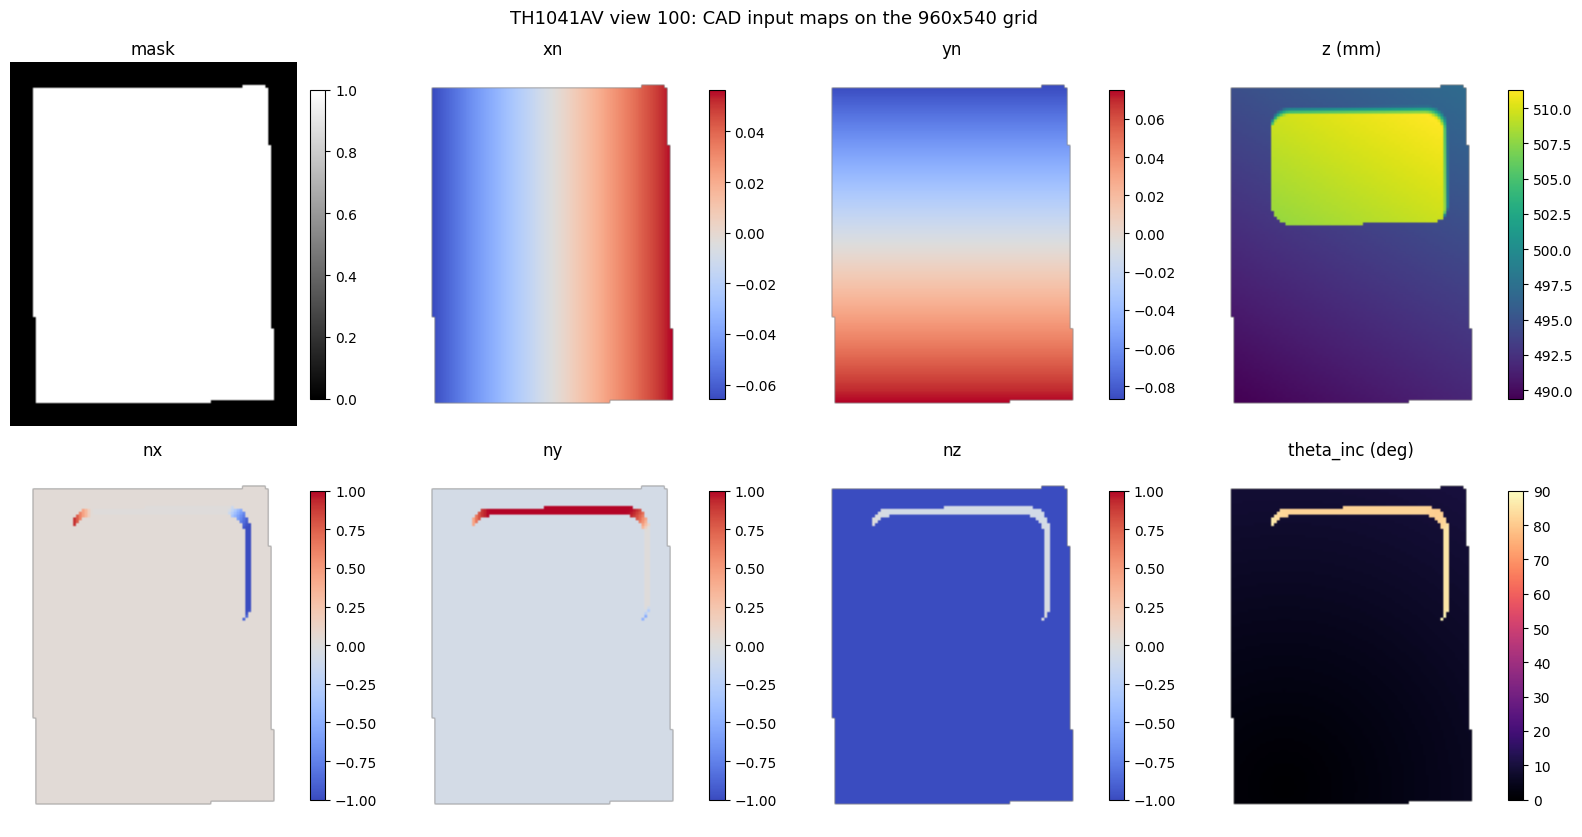

In [3]:
# ==========================================
# 3. RENDER THE 7 INPUT MAPS FOR ONE VIEW
# ==========================================
T_cam = rs.real_camera_pose(DIRS["raw"], VIEW_IDX, T_avg)
render = renderer.render(cam, T_cam)
mask = render["mask"]
features = rs.feature_stack(render)            # (7, H, W), NaN outside the CAD

print(f"View {VIEW_IDX}: camera at {np.round(T_cam[:3, 3], 1)} mm in the CAD frame, "
      f"{np.linalg.norm(T_cam[:3, 3]):.0f} mm from the CAD origin")
print(f"Feature stack {features.shape}, CAD pixels {mask.sum()} ({mask.mean() * 100:.2f}% of the frame)")
display(pd.DataFrame({k: [np.nanmin(f), np.nanmean(f), np.nanmax(f)] for k, f in zip(rs.FEATURE_NAMES, features)},
                     index=["min", "mean", "max"]).round(3))

v0, v1, u0, u1 = rs.mask_bbox(mask, margin=8)
panels = [("mask", "gray", None), ("xn", "coolwarm", None), ("yn", "coolwarm", None), ("z", "viridis", None),
          ("nx", "coolwarm", (-1, 1)), ("ny", "coolwarm", (-1, 1)), ("nz", "coolwarm", (-1, 1)), ("theta_inc", "magma", (0, 90))]
fig, axes = plt.subplots(2, 4, figsize=(16, 8.5))
for ax, (name, cmap, lim) in zip(axes.ravel(), panels):
    img = (mask.astype(float) if name == "mask" else render[name])[v0:v1, u0:u1]
    im = ax.imshow(img, cmap=cmap, vmin=lim[0] if lim else None, vmax=lim[1] if lim else None)
    ax.set_title(name + (" (mm)" if name == "z" else " (deg)" if name == "theta_inc" else ""))
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
fig.suptitle(f"{WORKPIECE} view {VIEW_IDX}: CAD input maps on the {cam.width}x{cam.height} grid", fontsize=13)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f"part1_maps_view{VIEW_IDX}.png"), dpi=120)
plt.show()

## 4. Check A: rendered geometry is exact
Unproject the rendered depth to 3D, move it to the CAD frame and measure the distance to the mesh (should be ~0; the ray-caster works in float32, so up to a few hundredths of a mm). Then project the 3D points back and check they land on the pixel they came from.

In [4]:
# ==========================================
# 4. CHECK A: UNPROJECT -> MESH DISTANCE, PROJECT -> SAME PIXEL
# ==========================================
P_cam = cam.unproject(render["z"], mask)
P_cad = rs.transform_points(P_cam, T_cam)
dist = renderer.scene.compute_distance(o3d.core.Tensor(P_cad.astype(np.float32))).numpy()

u_back, v_back, _ = cam.project(P_cam)
vs, us = np.nonzero(mask)
pix_err = np.hypot(u_back - us, v_back - vs)

print(f"Distance of rendered pixels to the CAD mesh: mean {dist.mean():.1e} mm, 99.9% {np.percentile(dist, 99.9):.1e} mm, max {dist.max():.1e} mm")
print(f"Round trip pixel error: max {pix_err.max():.1e} px")
print("PASS" if dist.max() < 0.1 and pix_err.max() < 1e-6 else "FAIL")

Distance of rendered pixels to the CAD mesh: mean 1.8e-04 mm, 99.9% 2.3e-02 mm, max 3.4e-02 mm
Round trip pixel error: max 0.0e+00 px
PASS


## 5. Check B: normals and angle of incidence
- Every rendered normal must equal its hit triangle's normal rotated into the camera frame (up to the sign flip that makes it face the camera). `flipped` counts pixels where the mesh normal pointed away from the camera (0 for a correctly oriented STL).
- $\theta_{inc}$ must equal the AoI definition used in notebooks 8 and 9 (`camera_dir = -point`, angle to the normal), so old and new results stay comparable.

Normals vs mesh triangles: max abs diff 3.2e-05; unit length error 7.4e-08
Normals flipped to face the camera: 0 px; normals facing away after orientation: 0
theta_inc vs AoI of notebooks 8/9: max diff 8.4e-12 deg
PASS


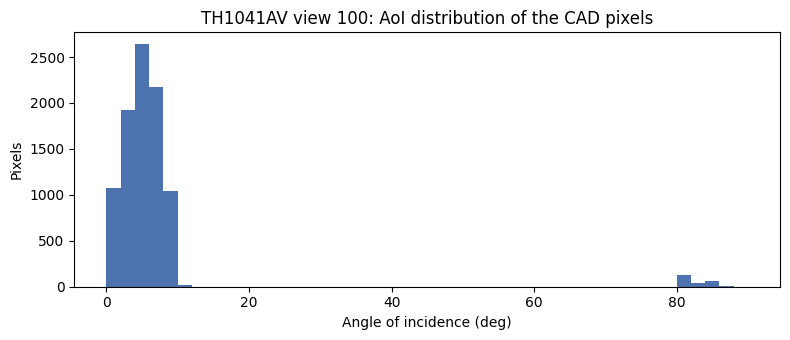

In [5]:
# ==========================================
# 5. CHECK B: NORMALS AND ANGLE OF INCIDENCE
# ==========================================
n = np.stack([render["nx"][mask], render["ny"][mask], render["nz"][mask]], axis=-1)
tri_n = np.asarray(renderer.mesh.triangle_normals)[render["prim_id"][mask]] @ T_cam[:3, :3]   # R^T n_tri
n_err = np.abs(n - np.sign((n * tri_n).sum(1))[:, None] * tri_n).max()

# AoI as in notebooks 8 / 9
cam_dir = -P_cam / np.linalg.norm(P_cam, axis=1, keepdims=True)
aoi_old = np.degrees(np.arccos(np.clip((cam_dir * n).sum(1), -1, 1)))
aoi_old = np.where(aoi_old > 90, 180 - aoi_old, aoi_old)
aoi_err = np.abs(aoi_old - render["theta_inc"][mask]).max()

print(f"Normals vs mesh triangles: max abs diff {n_err:.1e}; unit length error {np.abs(np.linalg.norm(n, axis=1) - 1).max():.1e}")
print(f"Normals flipped to face the camera: {render['flipped'].sum()} px; normals facing away after orientation: {((cam_dir * n).sum(1) < 0).sum()}")
print(f"theta_inc vs AoI of notebooks 8/9: max diff {aoi_err:.1e} deg")
print("PASS" if n_err < 1e-3 and aoi_err < 1e-3 else "FAIL")

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(render["theta_inc"][mask], bins=np.arange(0, 91, 2), color="#4C72B0")
ax.set_xlabel("Angle of incidence (deg)")
ax.set_ylabel("Pixels")
ax.set_title(f"{WORKPIECE} view {VIEW_IDX}: AoI distribution of the CAD pixels")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, f"part1_aoi_hist_view{VIEW_IDX}.png"), dpi=120)
plt.show()

## 6. Check C: CAD outline on the real images
Renders at the native 1920×1080 grid and draws the CAD edges (silhouette, creases, pocket rim) in green on the real colour image and the real depth image saved by `2_2`. If the intrinsics and the pose chain are right, the outline sits on the workpiece. `T_average` itself is off by ~2 mm / ~2° (found and corrected in 12_2), which is about 3–5 native pixels here, so look for a small consistent shift, not a gross one.

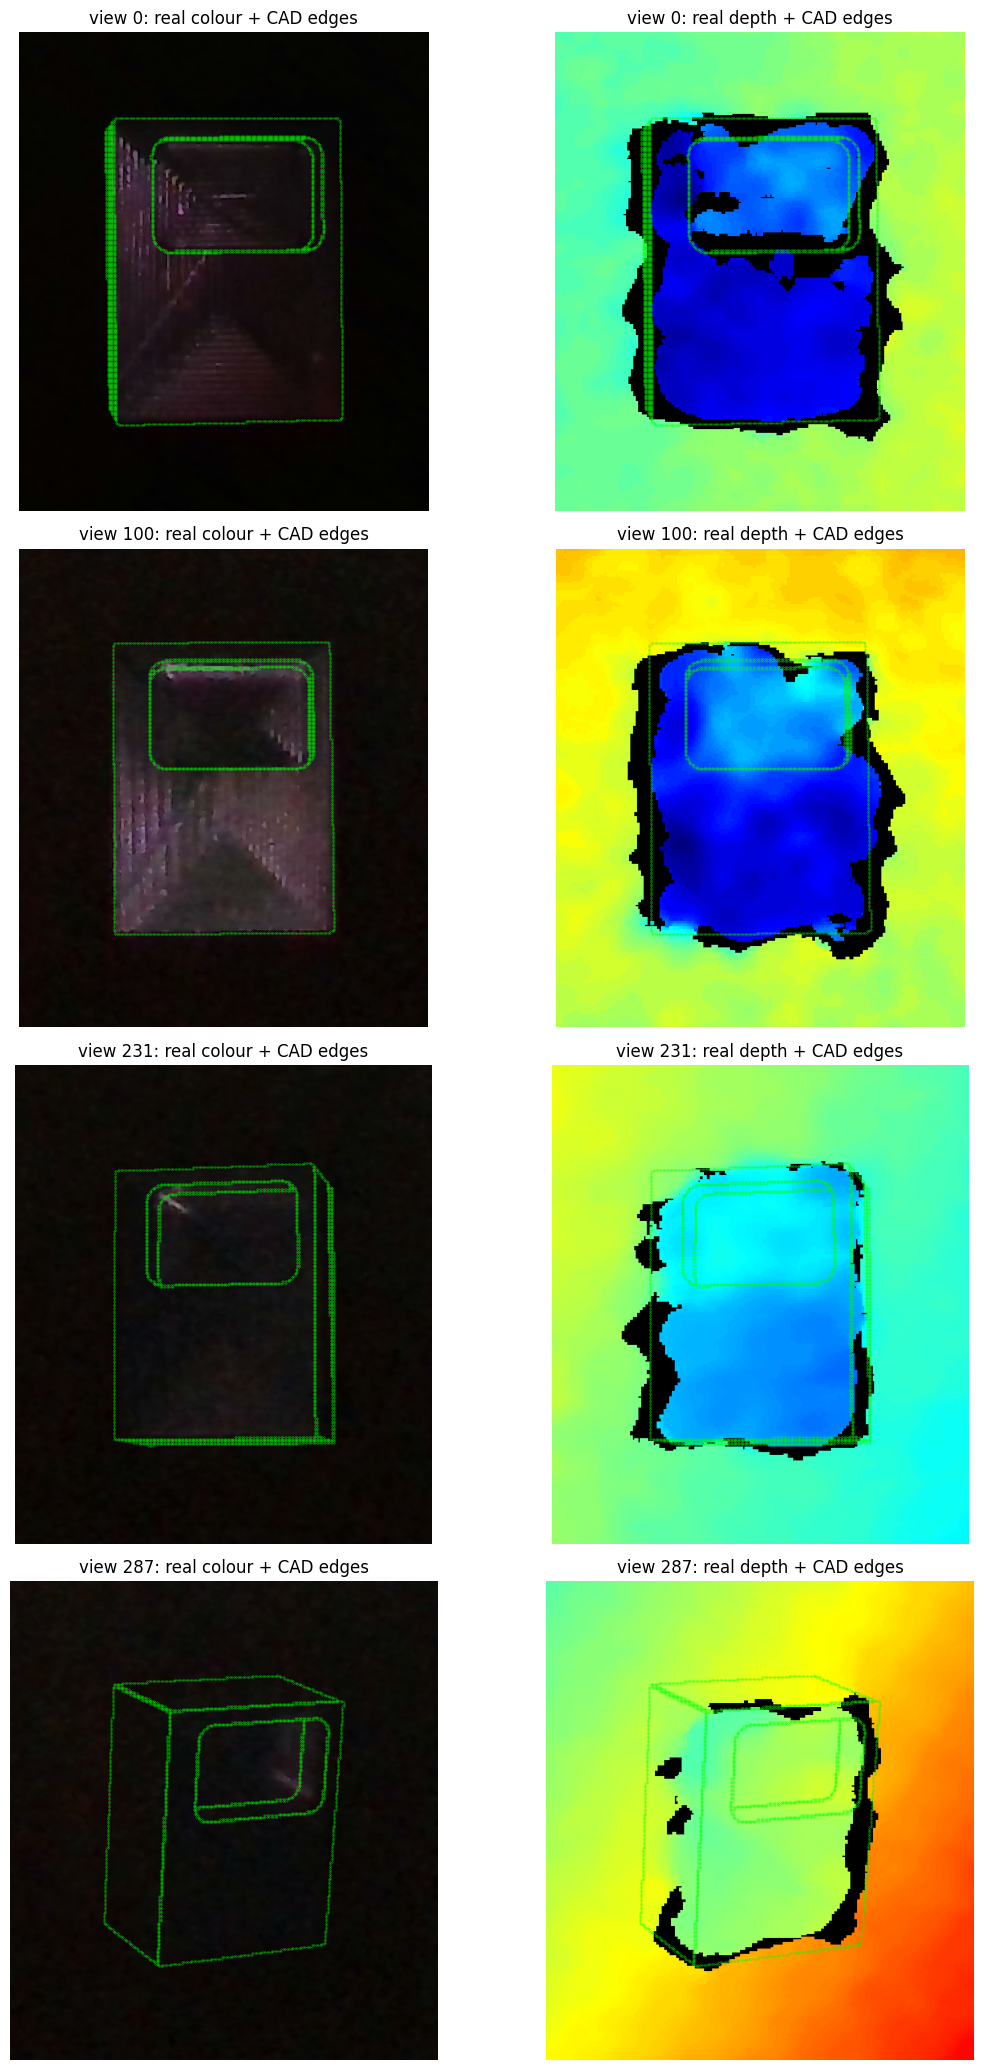

In [6]:
# ==========================================
# 6. CHECK C: CAD EDGES OVER THE REAL COLOUR / DEPTH IMAGES
# ==========================================
OVERLAY_VIEWS = [0, 100, 231, 287]

fig, axes = plt.subplots(len(OVERLAY_VIEWS), 2, figsize=(12, 5.2 * len(OVERLAY_VIEWS)))
for row, v in enumerate(OVERLAY_VIEWS):
    r_nat = renderer.render(cam_native, rs.real_camera_pose(DIRS["raw"], v, T_avg))
    edges = rs.cad_edges(r_nat)
    viz = cv2.cvtColor(cv2.imread(os.path.join(DIRS["raw"], f"view{v}_viz.png")), cv2.COLOR_BGR2RGB)
    b0, b1, a0, a1 = rs.mask_bbox(r_nat["mask"], margin=70)
    ys, xs = np.nonzero(edges[b0:b1, a0:a1])
    for col, (img, title) in enumerate([(viz[:, :rs.NATIVE_WIDTH], "colour"), (viz[:, rs.NATIVE_WIDTH:], "depth")]):
        ax = axes[row, col]
        ax.imshow(img[b0:b1, a0:a1])
        ax.scatter(xs, ys, s=0.15, c="lime", marker=".")
        ax.set_title(f"view {v}: real {title} + CAD edges")
        ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part1_overlay_real_images.png"), dpi=110)
plt.show()

## 7. Why the 960×540 grid
`2_2` voxel-downsampled every saved scan at 0.5 mm. At the native 1920×1080 grid, one pixel covers only ~0.37 mm of surface at 500 mm, *smaller* than the 0.5 mm point spacing, so many pixels stay empty even where the sensor did measure. Those empty pixels would look like dropouts (`y_drop = 1`) but are only downsampling gaps.

The test: take CAD pixels on **flat, interior** surfaces (θ_inc < 45°, more than 3 mm from any CAD edge), where the sensor returns depth almost everywhere, and count how many get a real point at each grid size. The right grid is the finest one where this fill rate stops climbing. Coarser grids gain almost nothing there and lose detail at edges and in the pocket.

Mean over views [0, 100, 231, 287]. fill = fraction of CAD pixels that got a real point.


,,mm_per_px,fill_flat_interior,fill_all_cad,pts_per_px
scale,grid,,,,
1,1920x1080,0.375,0.683,0.543,1.00
2,960x540,0.751,0.937,0.752,4.00
3,640x360,1.126,0.958,0.772,8.25
4,480x270,1.501,0.960,0.786,15.00


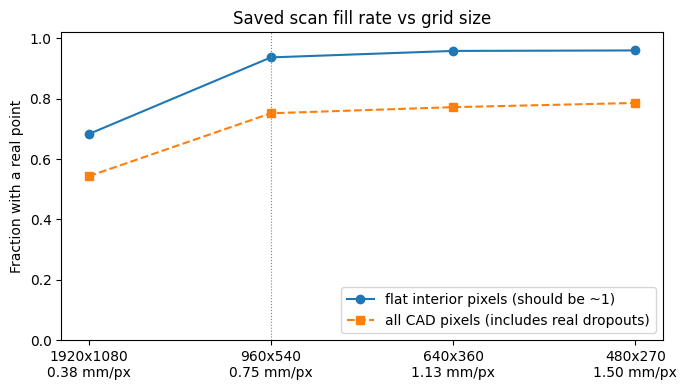

In [8]:
# ==========================================
# 7. GRID SIZE: HOW WELL THE SAVED SCAN FILLS EACH GRID
# ==========================================
SCALES = [1, 2, 3, 4]               # 1920x1080, 960x540, 640x360, 480x270
SCALE_VIEWS = [0, 100, 231, 287]

rows = []
for v in SCALE_VIEWS:
    P = rs.load_real_scan_cam(DIRS["raw"], v)
    T_v = rs.real_camera_pose(DIRS["raw"], v, T_avg)
    for s in SCALES:
        c = cam_native.downscaled(s)
        r = renderer.render(c, T_v)
        Z, count = rs.project_to_grid(c, P[rs.near_cad_surface(c, P, r, GATE_MM)], reduce="median")
        m, has = r["mask"], np.isfinite(Z)
        mm_per_px = np.nanmedian(r["z"]) / c.fx
        edge_dist_mm = cv2.distanceTransform((~rs.cad_edges(r)).astype(np.uint8), cv2.DIST_L2, 3) * mm_per_px
        flat = m & (r["theta_inc"] < 45) & (edge_dist_mm > 3.0)
        rows.append(dict(view=v, scale=s, grid=f"{c.width}x{c.height}", mm_per_px=mm_per_px,
                         fill_flat_interior=has[flat].mean(), fill_all_cad=has[m].mean(),
                         pts_per_px=np.median(count[m & (count > 0)])))
df_scale = pd.DataFrame(rows)
summary = df_scale.groupby(["scale", "grid"])[["mm_per_px", "fill_flat_interior", "fill_all_cad", "pts_per_px"]].mean()
print(f"Mean over views {SCALE_VIEWS}. fill = fraction of CAD pixels that got a real point.")
display(summary.round(3))

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(SCALES))
ax.plot(x, summary["fill_flat_interior"], "o-", label="flat interior pixels (should be ~1)")
ax.plot(x, summary["fill_all_cad"], "s--", label="all CAD pixels (includes real dropouts)")
ax.axvline(SCALES.index(GRID_SCALE), color="grey", lw=0.8, ls=":")
ax.set_xticks(x)
ax.set_xticklabels([f"{g}\n{mm:.2f} mm/px" for g, mm in zip(summary.index.get_level_values("grid"), summary["mm_per_px"])])
ax.set_ylim(0, 1.02)
ax.set_ylabel("Fraction with a real point")
ax.set_title("Saved scan fill rate vs grid size")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "part1_grid_size_fill.png"), dpi=120)
plt.show()

## 8. 3D view (optional)
Camera frame of `VIEW_IDX`: rendered CAD pixels coloured by angle of incidence (blue = face-on, red = grazing), real workpiece points (grey: points within `GATE_MM` of the CAD depth at their pixel) and the camera axes at the origin.

In [10]:
# ==========================================
# 8. 3D VIEW: RENDERED CAD (AoI colours) VS REAL SCAN, CAMERA FRAME
# ==========================================
if SHOW_O3D:
    pcd_cad = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(P_cam))
    pcd_cad.colors = o3d.utility.Vector3dVector(plt.get_cmap("jet")(render["theta_inc"][mask] / 90.0)[:, :3])
    P_real = rs.load_real_scan_cam(DIRS["raw"], VIEW_IDX)
    pcd_real = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(P_real[rs.near_cad_surface(cam, P_real, render, GATE_MM)]))
    pcd_real.paint_uniform_color([0.55, 0.55, 0.55])
    cam_frame = o3d.geometry.TriangleMesh.create_coordinate_frame(size=40.0)
    o3d.visualization.draw_geometries([pcd_cad, pcd_real, cam_frame],
                                      window_name=f"View {VIEW_IDX}: CAD pixels (AoI colours) vs real scan (grey)")

## Summary of Part 1 (results on test_11_real_pocket)
- **Intrinsics** (native 1920×1080): factory calibration of the D435I, $f_x = 1360.67$, $f_y = 1360.56$, $c_x = 975.66$, $c_y = 560.15$, zero distortion (`config/realsense_d435i_335222073706.txt`). Fitting them from the saved depth images alone gives the same values to within 0.5 px on every view, so the scans used the 1920×1080 colour stream.
- **Renderer**: exact to float32 precision (check A), normals and AoI match the mesh and the old AoI definition (check B), and the CAD outline lands on the workpiece in the real images (check C).
- **Grid**: 960×540 (~0.75 mm per pixel). At native 1920×1080, only ~68% of flat interior pixels get a real point, because the saved scans were voxel-downsampled at 0.5 mm; at 960×540 it is ~94%, and coarser grids add only ~2% (section 7).
- **Next (Part 2, `12_2_real2sim_labels`)**: `T_average` (ICP fit of the CAD to the merged scans, from `4_1`) is off by ~2° and ~2 mm, so 12_2 corrects the CAD pose per workpiece (`T_cad_refined.npy`) and then makes the labels `y_drop` and `e_z`.